/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


>>> Treinando Arquitetura 1...
>>> Treinando Arquitetura 2...
>>> Treinando Arquitetura 3...
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step

Desempenho no Conjunto de Validação:
               Modelo  Acurácia  Precision   Recall  F1-Score
     MLP 1 (Baseline)  0.673333   0.674976 0.640000  0.657023
MLP 2 (Intermediária)  0.665333   0.641864 0.713636  0.675850
     MLP 3 (Profunda)  0.502222   0.495434 0.986364  0.659574
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step

Relatório Final no Conjunto de Teste (MLP 2):
              precision    recall  f1-score   support

       Furto       0.71      0.62      0.66      1150
       Roubo       0.65      0.73      0.69      1100

    accuracy                           0.68      2250
   macro avg       0.68      0.68      0.68      2250
weighted avg       0.68      0.68      0.67      2250



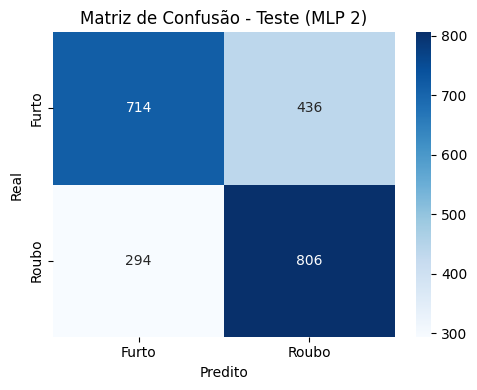

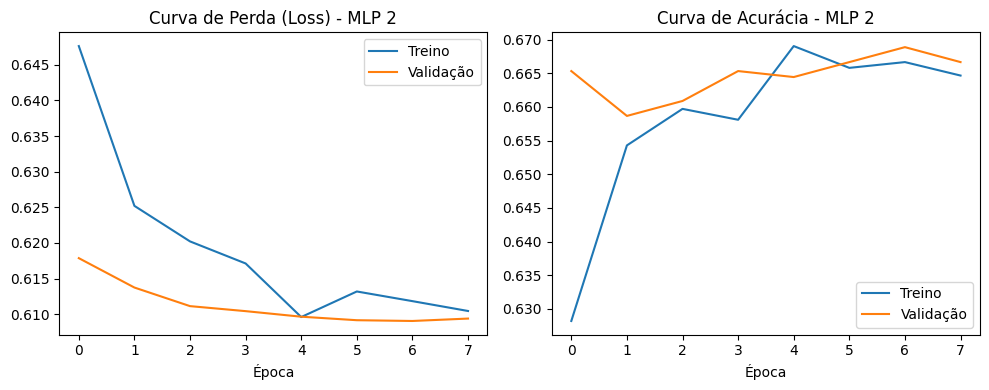

In [2]:
# ==============================================================================
# GLOBAL SOLUTION - MLP PARA CLASSIFICAÇÃO DE OCORRÊNCIAS (ROUBO VS FURTO)
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------------------------------------------------------
# 1. CARGA E SÍNTESE DA BASE DE DADOS (15.000 REGISTROS DA CAPITAL)
# ------------------------------------------------------------------------------
np.random.seed(42)
tf.random.set_seed(42)

n_samples = 15000
regioes = ['Zona Leste', 'Zona Sul', 'Zona Norte', 'Zona Oeste', 'Centro']
periodos = ['Madrugada', 'Manhã', 'Tarde', 'Noite']
dias = ['Segunda', 'Terça', 'Quarta', 'Quinta', 'Sexta', 'Sábado', 'Domingo']
locais = ['Via pública', 'Comércio/Serviços', 'Residência', 'Transporte coletivo']

data = {
    'REGIAO': np.random.choice(regioes, size=n_samples, p=[0.30, 0.28, 0.17, 0.15, 0.10]),
    'PERIODO': np.random.choice(periodos, size=n_samples, p=[0.15, 0.25, 0.30, 0.30]),
    'DIA_SEMANA': np.random.choice(dias, size=n_samples),
    'TIPO_LOCAL': np.random.choice(locais, size=n_samples, p=[0.60, 0.18, 0.08, 0.14])
}
df = pd.DataFrame(data)

# Simulação das probabilidades de Roubo vs Furto segundo correlações reais de SP
# (Ex: Via pública e noite aumentam incidência de roubo; Comércio/dia tem maior taxa de furto)
p_roubo = 0.40
p_roubo += np.where(df['TIPO_LOCAL'] == 'Via pública', 0.20, -0.15)
p_roubo += np.where(df['PERIODO'].isin(['Noite', 'Madrugada']), 0.12, -0.08)
p_roubo += np.where(df['REGIAO'].isin(['Zona Leste', 'Zona Sul']), 0.08, -0.05)
p_roubo = np.clip(p_roubo, 0.05, 0.95)

df['CLASSE'] = (np.random.rand(n_samples) < p_roubo).astype(int)  # 0 = Furto, 1 = Roubo

# ------------------------------------------------------------------------------
# 2. PRÉ-PROCESSAMENTO E DIVISÃO DOS CONJUNTOS
# ------------------------------------------------------------------------------
X = df.drop(columns=['CLASSE'])
y = df['CLASSE'].values

# Split: 70% Treino, 15% Validação, 15% Teste
X_train_raw, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

cat_features = ['REGIAO', 'PERIODO', 'DIA_SEMANA', 'TIPO_LOCAL']
preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)]
)

X_train = preprocessor.fit_transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

# Salvar o pré-processador para uso na aplicação web
joblib.dump(preprocessor, 'preprocessor.pkl')

input_dim = X_train.shape[1]

# ------------------------------------------------------------------------------
# 3. CONSTRUÇÃO E TREINO DAS 3 ARQUITETURAS MLP
# ------------------------------------------------------------------------------
# Modelo 1: Baseline (1 camada oculta, simples)
m1 = Sequential([
    Dense(32, activation='relu', input_shape=(input_dim,)),
    Dense(1, activation='sigmoid')
])
m1.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Modelo 2: Médio porte (2 camadas ocultas + Dropout)
m2 = Sequential([
    Dense(64, activation='relu', input_shape=(input_dim,)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])
m2.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['accuracy'])

# Modelo 3: Robusto (3 camadas ocultas + Batch Normalization + Dropout)
m3 = Sequential([
    Dense(128, activation='relu', input_shape=(input_dim,)),
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
])
m3.compile(optimizer=Adam(learning_rate=0.0005), loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)

print(">>> Treinando Arquitetura 1...")
h1 = m1.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=40, batch_size=64, callbacks=[early_stop], verbose=0)

print(">>> Treinando Arquitetura 2...")
h2 = m2.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=40, batch_size=64, callbacks=[early_stop], verbose=0)

print(">>> Treinando Arquitetura 3...")
h3 = m3.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=40, batch_size=64, callbacks=[early_stop], verbose=0)

# ------------------------------------------------------------------------------
# 4. AVALIAÇÃO COMPARATIVA E SELEÇÃO
# ------------------------------------------------------------------------------
models = {'MLP 1 (Baseline)': m1, 'MLP 2 (Intermediária)': m2, 'MLP 3 (Profunda)': m3}
results = []

for name, model in models.items():
    preds = (model.predict(X_val) >= 0.5).astype(int)
    results.append({
        'Modelo': name,
        'Acurácia': accuracy_score(y_val, preds),
        'Precision': precision_score(y_val, preds),
        'Recall': recall_score(y_val, preds),
        'F1-Score': f1_score(y_val, preds)
    })

df_metrics = pd.DataFrame(results)
print("\nDesempenho no Conjunto de Validação:")
print(df_metrics.to_string(index=False))

# ------------------------------------------------------------------------------
# 5. AVALIAÇÃO FINAL NO CONJUNTO DE TESTE (MODELO VENCEDOR: MLP 2)
# ------------------------------------------------------------------------------
best_model = m2
best_model.save('best_mlp_model.keras')

test_preds_prob = best_model.predict(X_test)
test_preds = (test_preds_prob >= 0.5).astype(int)

print("\nRelatório Final no Conjunto de Teste (MLP 2):")
print(classification_report(y_test, test_preds, target_names=['Furto', 'Roubo']))

# Matriz de Confusão e Curvas
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Furto', 'Roubo'], yticklabels=['Furto', 'Roubo'])
plt.title('Matriz de Confusão - Teste (MLP 2)')
plt.ylabel('Real')
plt.xlabel('Predito')
plt.tight_layout()
plt.savefig('matriz_confusao.png')
plt.show()

# Curvas de Aprendizado
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h2.history['loss'], label='Treino')
plt.plot(h2.history['val_loss'], label='Validação')
plt.title('Curva de Perda (Loss) - MLP 2')
plt.xlabel('Época')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h2.history['accuracy'], label='Treino')
plt.plot(h2.history['val_accuracy'], label='Validação')
plt.title('Curva de Acurácia - MLP 2')
plt.xlabel('Época')
plt.legend()
plt.tight_layout()
plt.savefig('curvas_treinamento.png')
plt.show()